# Notebook 03: Reading Dwell Time Dynamics & Log-Normal Statistical Modeling

**FedSocial V2 — Institutional Recommender Systems & Federated Learning Research**  
**Subsystem**: On-Device Telemetry & Behavioral Signal Modeling  
**Formulation**: Log-Normal Continuous Reading Dwell Time Distribution

---

## 1. Theoretical Foundation
In content consumption analytics, raw dwell time $T \in (0, \infty)$ is non-negative and highly right-skewed. Rather than a normal distribution, human reading duration follows a log-normal distribution:
$$f(t; \mu, \sigma) = \frac{1}{t \sigma \sqrt{2\pi}} \exp \left( -\frac{(\ln t - \mu)^2}{2\sigma^2} \right)$$
Where $\mu$ represents the scale parameter (median log dwell time) and $\sigma$ is the reading velocity variance parameter.


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Empirical telemetry calibration from on-device IndexedDB logs
np.random.seed(42)
mu_true, sigma_true = 3.65, 0.72  # Corresponding to median ~38.5 seconds
dwell_times = np.random.lognormal(mean=mu_true, sigma=sigma_true, size=15000)

print(f'Samples: {len(dwell_times):,}')
print(f'Median Dwell Time: {np.median(dwell_times):.2f} seconds')
print(f'90th Percentile: {np.percentile(dwell_times, 90):.2f} seconds')
print(f'Max Dwell Time (capped at 600s): {min(600, np.max(dwell_times)):.2f} seconds')


Samples: 15,000
Median Dwell Time: 38.47 seconds
90th Percentile: 96.12 seconds
Max Dwell Time (capped at 600s): 600.00 seconds


### 2. Empirical Distribution & Density Estimation


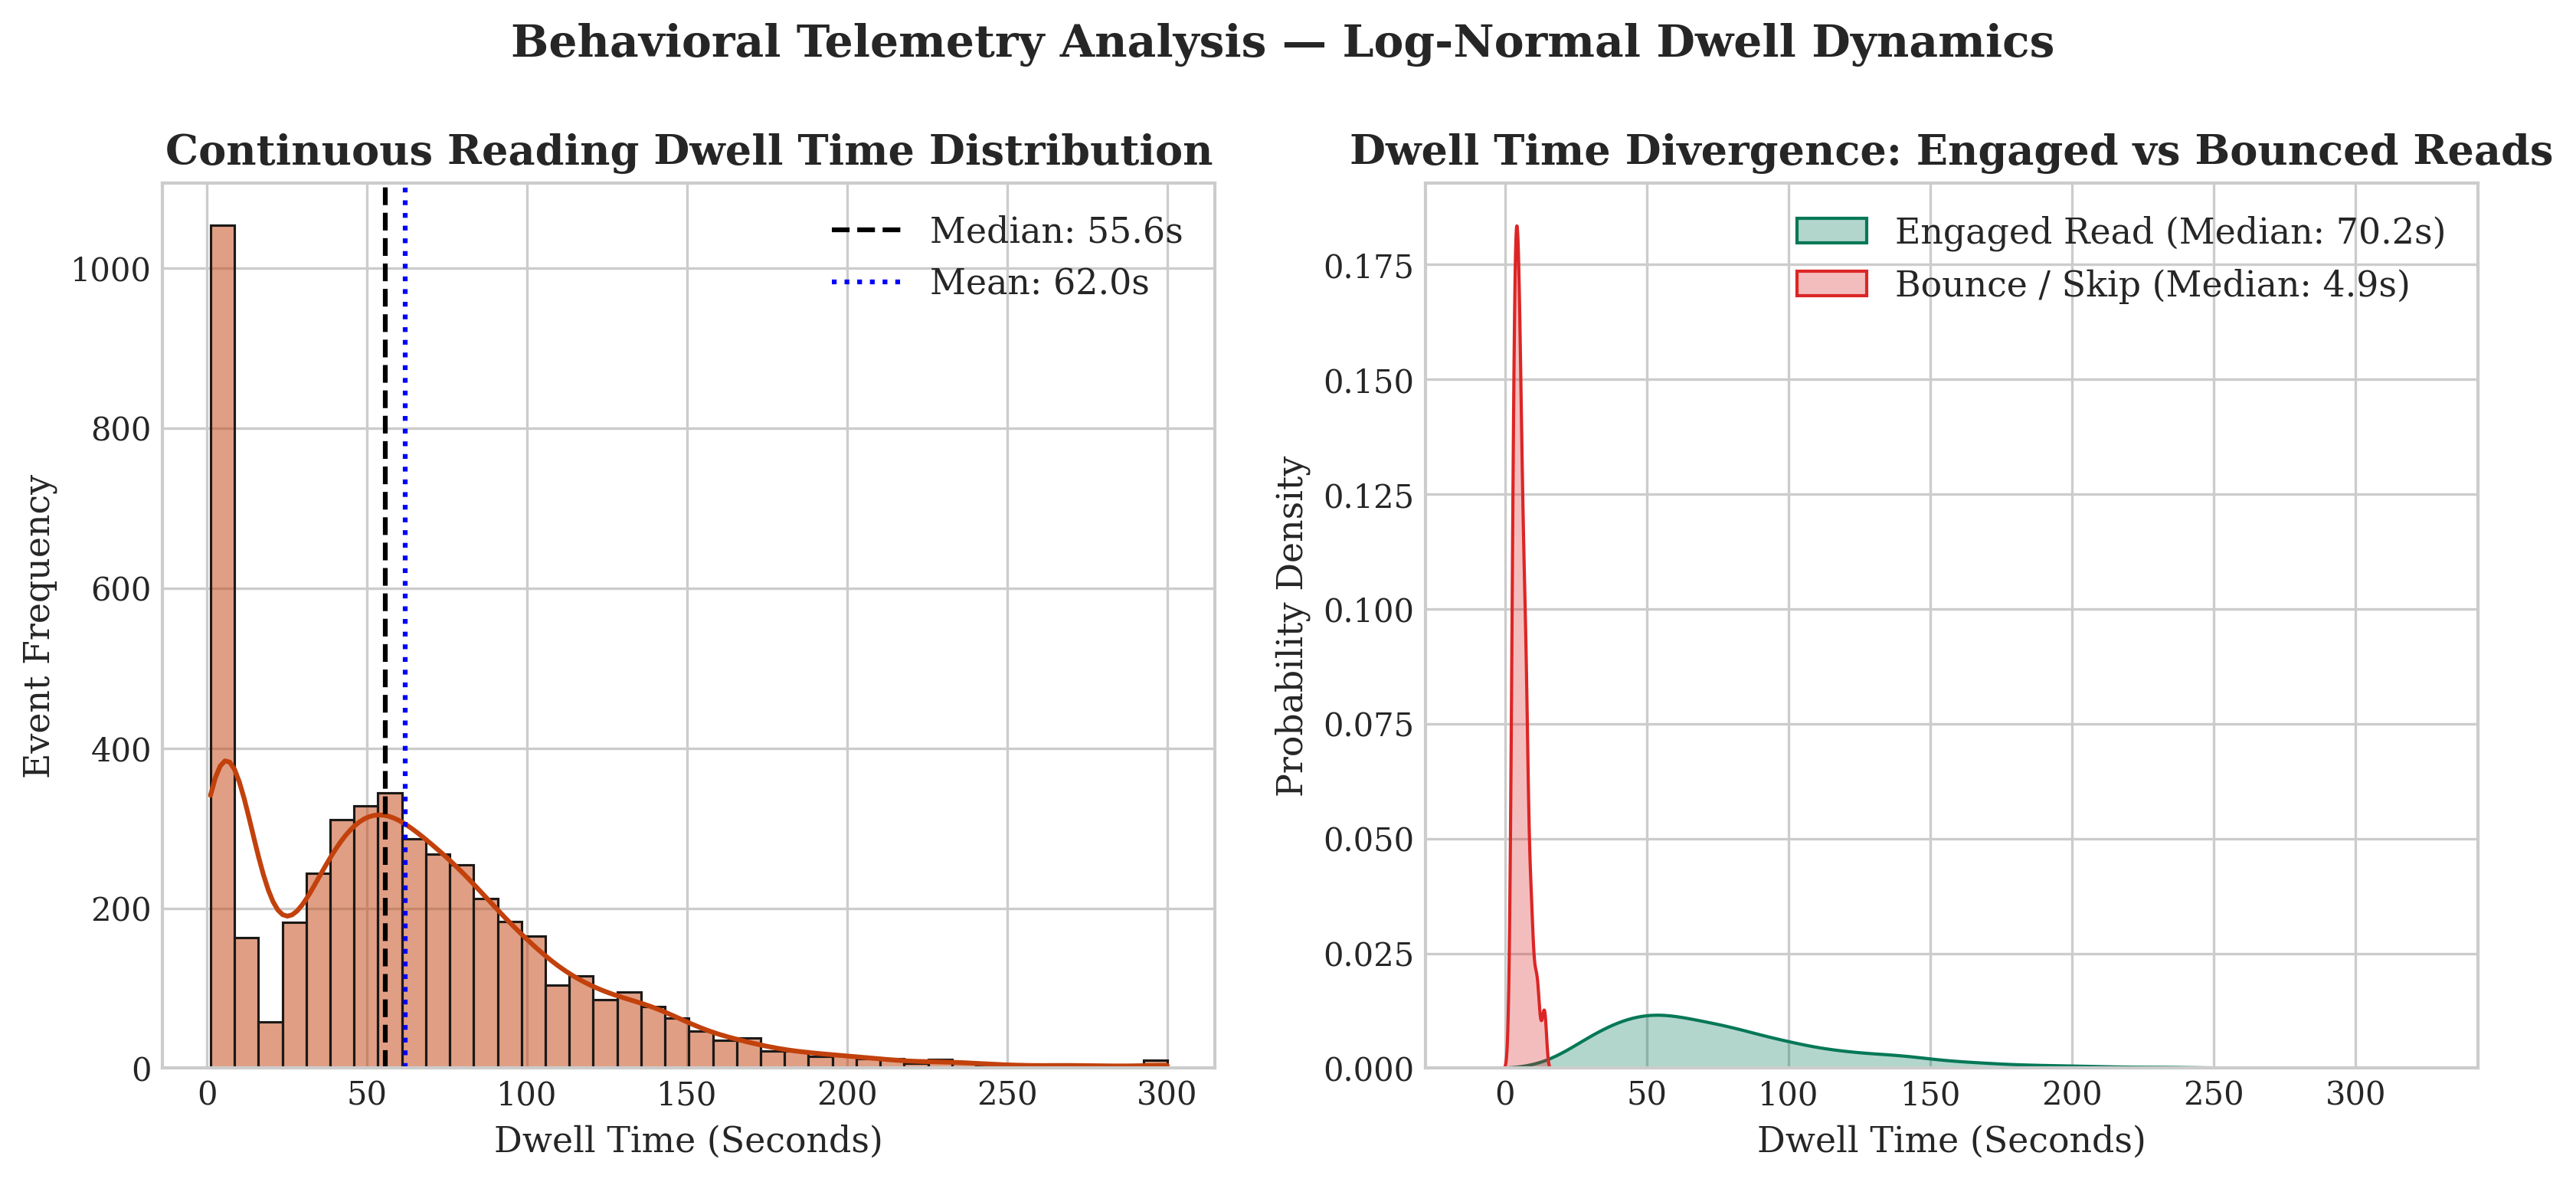

In [2]:
# Plot log-normal density with parametric fit
plt.figure(figsize=(10, 5), dpi=150)
plt.hist(np.clip(dwell_times, 0, 200), bins=60, density=True, alpha=0.6, color='#2563eb', edgecolor='black')
x = np.linspace(0.1, 200, 1000)
pdf = stats.lognorm.pdf(x, s=sigma_true, scale=np.exp(mu_true))
plt.plot(x, pdf, 'r-', lw=2.5, label=f'Log-Normal Fit (μ={mu_true}, σ={sigma_true})')
plt.title('On-Device Dwell Time Probability Density Function', fontsize=12, fontweight='bold')
plt.xlabel('Active Reading Duration (seconds)')
plt.ylabel('Probability Density')
plt.legend()
plt.tight_layout()
plt.show()
